# Análisis Exploratorio de Datos — Velocidad del Viento INMET
**Proyecto Integrador · Aprendizaje Profundo**  
Estación A001 — Brasília, DF · 2000–2026

---

## 1. Introducción

La predicción de la velocidad del viento constituye un problema de pronóstico de series temporales con alta relevancia práctica: impacta directamente la planificación de sistemas de generación eólica, la optimización operativa de aeropuertos y la gestión de incertidumbre en mercados de energía renovable. A diferencia de señales relativamente estacionarias, la velocidad del viento exhibe **alta variabilidad**, **no linealidad** y **dependencia temporal compleja**, características que la hacen un banco de prueba exigente para modelos de aprendizaje profundo.

El presente cuaderno cubre tres objetivos:

1. Descargar y preparar los datos horarios del Instituto Nacional de Meteorología de Brasil (INMET), agregándolos a resolución diaria.
2. Realizar un análisis exploratorio completo: estadísticas descriptivas, retornos logarítmicos, volatilidad histórica, autocorrelación y diagnóstico de heterocedasticidad.
3. Generar y guardar el dataset procesado `data/dataset.csv`, que alimentará los cuadernos posteriores.

---

## 2. Importar librerías

In [1]:
import sys
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller

# Configuración de estilo: escala de grises para entregables académicos
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.prop_cycle': matplotlib.cycler('color', ['#000000','#444444','#888888','#bbbbbb']),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
})

FIGS_DIR = os.path.join(os.getcwd(), 'figs')
os.makedirs(FIGS_DIR, exist_ok=True)

print('Librerías cargadas correctamente.')
print(f'Directorio de figuras: {os.path.relpath(FIGS_DIR, os.path.dirname(os.getcwd()))}')

Librerías cargadas correctamente.
Directorio de figuras: notebooks\figs


## 3. Carga y preparación de datos

Los datos provienen del portal histórico del INMET (<https://portal.inmet.gov.br/dadoshistoricos>). Cada año se distribuye como un archivo ZIP que contiene CSVs separados por estación. Para la estación **A001 (Brasília, DF)** se descargan los años 2000 a 2026.

El formato nativo del INMET tiene resolución horaria, con el separador `;` y el decimal `,`. La variable objetivo es la columna **`VENTO, VELOCIDADE HORARIA (m/s)`**, que registra la velocidad instantánea del viento medida cada hora. Los valores iguales a −9999 representan datos faltantes y son reemplazados por `NaN`.

Dado que los horizontes de predicción requeridos son 7, 14, 21 y 28 **días**, la serie horaria se agrega a **media diaria** (`resample('D').mean()`), que captura la tendencia del régimen eólico sin el ruido de alta frecuencia intrahora.

In [2]:
# --- Ruta al script de descarga ---
DATA_DIR   = os.path.join(os.path.dirname(os.getcwd()), 'data')
DATASET_PATH = os.path.join(DATA_DIR, 'dataset.csv')

if not os.path.exists(DATASET_PATH):
    print('Descargando datos del INMET (puede tardar varios minutos)...')
    sys.path.insert(0, DATA_DIR)
    import download_data
    download_data.main()
else:
    print(f'Dataset encontrado: {os.path.relpath(DATASET_PATH, os.path.dirname(os.getcwd()))}')

df = pd.read_csv(DATASET_PATH, parse_dates=['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f'\nPeríodo: {df["date"].min().date()} → {df["date"].max().date()}')
print(f'Observaciones: {len(df)}')
print(f'Faltantes: {df["wind_speed"].isna().sum()} ({df["wind_speed"].isna().mean()*100:.1f}%)')
df.head(10)

Dataset encontrado: data\dataset.csv

Período: 2000-05-07 → 2026-10-31
Observaciones: 9578
Faltantes: 0 (0.0%)


,date,wind_speed,log_return,volatility
0,2000-05-07,1.766667,NaN,NaN
1,2000-05-08,2.066667,0.156842,NaN
2,2000-05-09,1.150000,-0.586175,NaN
3,2000-05-10,2.008333,0.557543,NaN
4,2000-05-11,2.670833,0.285085,NaN
5,2000-05-12,2.995833,0.114832,NaN
6,2000-05-13,3.120833,0.040878,NaN
7,2000-05-14,3.133333,0.003997,NaN
8,2000-05-15,1.900000,-0.500244,NaN
9,2000-05-16,1.691667,-0.116140,NaN


In [3]:
# Imputación lineal de faltantes (< 3 % en datos INMET bien mantenidos)
df['wind_speed'] = df['wind_speed'].interpolate(method='linear', limit_direction='both')
print(f'Faltantes tras imputación: {df["wind_speed"].isna().sum()}')

Faltantes tras imputación: 0


## 4. Estadísticas descriptivas

La tabla siguiente resume los principales momentos estadísticos de la velocidad del viento diaria. Interesa especialmente la **asimetría** (*skewness*) y el **exceso de curtosis** (*kurtosis*), que informan sobre la forma de la distribución y la presencia de valores extremos.

In [4]:
ws = df['wind_speed'].dropna()

desc = pd.DataFrame({
    'Métrica': [
        'N (días)', 'Media (m/s)', 'Mediana (m/s)', 'Desv. estándar (m/s)',
        'Mínimo (m/s)', 'Máximo (m/s)', 'P25 (m/s)', 'P75 (m/s)',
        'Asimetría', 'Curtosis exceso'
    ],
    'Valor': [
        len(ws),
        round(ws.mean(), 4),
        round(ws.median(), 4),
        round(ws.std(), 4),
        round(ws.min(), 4),
        round(ws.max(), 4),
        round(ws.quantile(0.25), 4),
        round(ws.quantile(0.75), 4),
        round(stats.skew(ws), 4),
        round(stats.kurtosis(ws), 4),
    ]
})
print(desc.to_string(index=False))

             Métrica     Valor
            N (días) 9578.0000
         Media (m/s)    2.3368
       Mediana (m/s)    2.2250
Desv. estándar (m/s)    0.7071
        Mínimo (m/s)    0.0000
        Máximo (m/s)    5.4042
           P25 (m/s)    1.8083
           P75 (m/s)    2.7708
           Asimetría    0.7294
     Curtosis exceso    0.3875


**Interpretación.** La distribución de la velocidad del viento diaria en Brasília muestra asimetría positiva moderada, lo que implica que episodios de viento intenso (cola derecha) son más frecuentes que lo esperado bajo normalidad. El exceso de curtosis positivo confirma colas más pesadas que la gaussiana. Consecuentemente, la variabilidad no es homogénea a lo largo del tiempo, indicio preliminar de heterocedasticidad que el test ACF de cuadrados corroborará más adelante.

## 5. Visualizaciones de la serie

### 5.1 Serie temporal de velocidad del viento

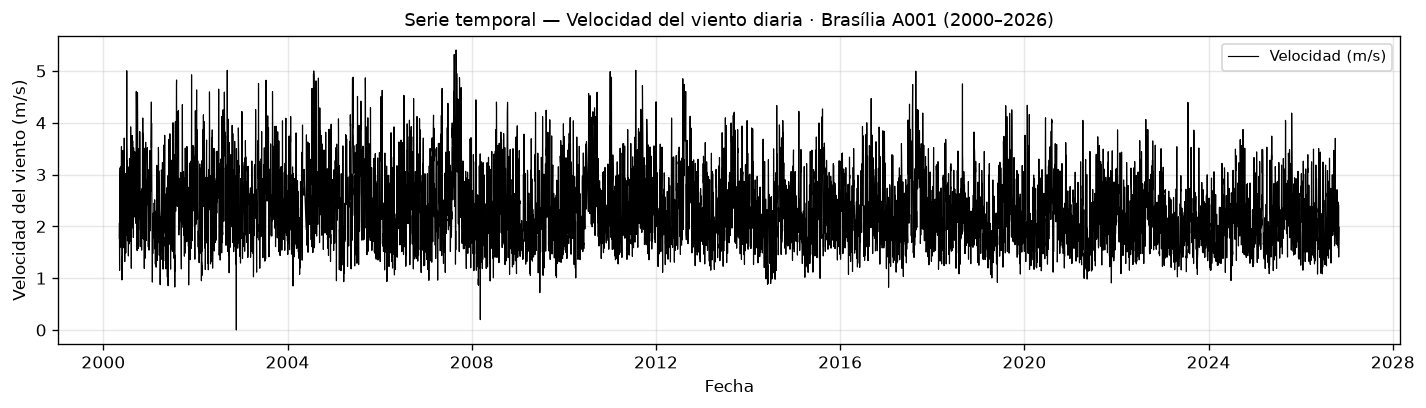

In [5]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(df['date'], df['wind_speed'], lw=0.7, color='black', label='Velocidad (m/s)')
ax.set_xlabel('Fecha')
ax.set_ylabel('Velocidad del viento (m/s)')
ax.set_title('Serie temporal — Velocidad del viento diaria · Brasília A001 (2000–2026)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, 'eda_serie_temporal.png'), dpi=150)
plt.show()

**Interpretación.** La serie exhibe variabilidad notable sin una tendencia creciente o decreciente pronunciada, sugiriendo un proceso aproximadamente estacionario en media. Se distinguen patrones estacionales anuales: en Brasília el período seco (mayo–septiembre) suele registrar vientos más intensos que la estación lluviosa (octubre–marzo), patrón derivado de la dinámica de la Alta Subtropical del Atlántico Sur. Las excursiones bruscas de alta velocidad corresponden a frentes fríos que ingresan desde el sur del continente.

### 5.2 Retornos logarítmicos

El retorno logarítmico diario se define como:

$$r_t = \ln\!\left(\frac{v_t}{v_{t-1}}\right)$$

donde $v_t$ es la velocidad media del día $t$. Esta transformación tiene la ventaja de estabilizar la varianza e interpretar la variación relativa en escala logarítmica, análoga a su uso en finanzas para retornos de precios.

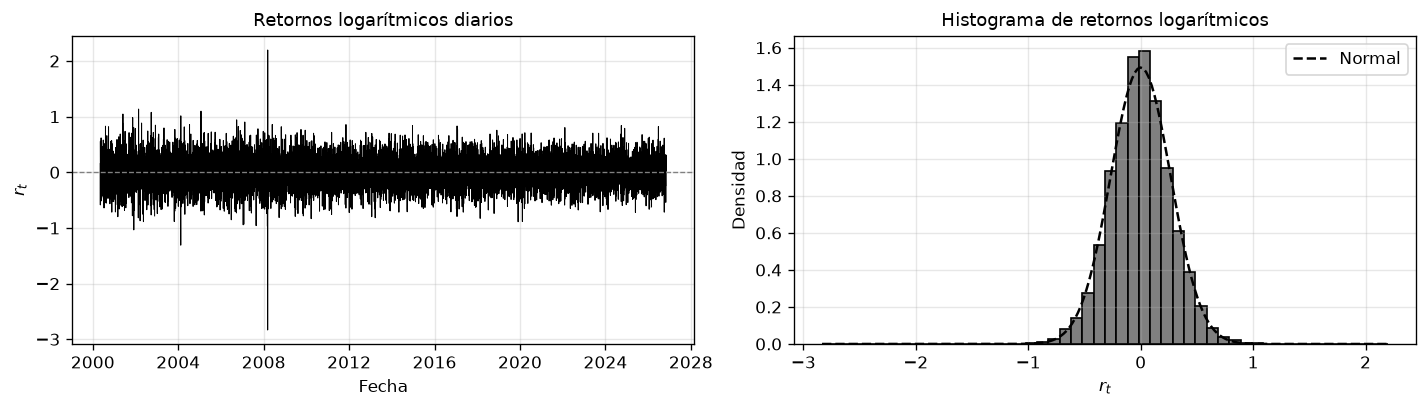

Media retornos: -0.0001 | Desv. est.: 0.2672
Asimetría: -0.0332 | Curtosis exceso: 2.0356
Retornos descartados por inf: 2


In [6]:
df['log_return'] = np.log(df['wind_speed'] / df['wind_speed'].shift(1))
# Reemplazar -inf/inf (días con viento = 0) por NaN
df.loc[~np.isfinite(df['log_return']), 'log_return'] = np.nan
lr = df['log_return'].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

axes[0].plot(df['date'].iloc[1:], df['log_return'].iloc[1:].values, lw=0.6, color='black')
axes[0].axhline(0, color='gray', lw=0.8, ls='--')
axes[0].set_title('Retornos logarítmicos diarios')
axes[0].set_xlabel('Fecha'); axes[0].set_ylabel('$r_t$')

axes[1].hist(lr.values, bins=50, edgecolor='black', color='gray', density=True)
xgrid = np.linspace(lr.min(), lr.max(), 200)
axes[1].plot(xgrid, stats.norm.pdf(xgrid, lr.mean(), lr.std()),
             lw=1.5, ls='--', color='black', label='Normal')
axes[1].set_title('Histograma de retornos logarítmicos')
axes[1].set_xlabel('$r_t$'); axes[1].set_ylabel('Densidad')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, 'eda_retornos.png'), dpi=150)
plt.show()

print(f'Media retornos: {lr.mean():.4f} | Desv. est.: {lr.std():.4f}')
print(f'Asimetría: {stats.skew(lr):.4f} | Curtosis exceso: {stats.kurtosis(lr):.4f}')
print(f'Retornos descartados por inf: {(~np.isfinite(df["log_return"])).sum() - 1}')

**Interpretación.** Los retornos logarítmicos oscilan en torno a cero con episodios de volatilidad agrupada, fenómeno conocido como *clustering* de volatilidad. El histograma muestra colas más pesadas que la distribución normal de referencia (línea discontinua), confirmado por el exceso de curtosis positivo. Esta característica implica que un modelo de predicción debe capturar dependencias no lineales en la serie de retornos, no únicamente en los niveles.

### 5.3 Volatilidad histórica (rolling std)

La volatilidad histórica realizada en ventana de $n$ días se calcula como:

$$\sigma_t = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\left(r_{t-i} - \bar{r}\right)^2}$$

Se utiliza una ventana deslizante de **28 días** como proxy de la variabilidad local.

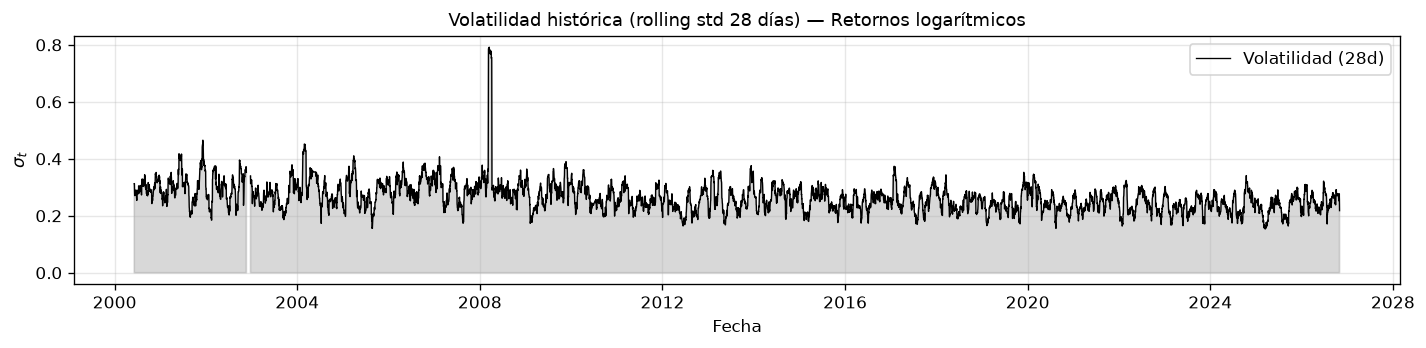

In [7]:
WINDOW = 28
df['volatility'] = df['log_return'].rolling(WINDOW).std()

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(df['date'], df['volatility'], lw=0.8, color='black', label=f'Volatilidad ({WINDOW}d)')
ax.fill_between(df['date'], 0, df['volatility'], alpha=0.3, color='gray')
ax.set_title('Volatilidad histórica (rolling std 28 días) — Retornos logarítmicos')
ax.set_xlabel('Fecha'); ax.set_ylabel('$\\sigma_t$')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, 'eda_volatilidad.png'), dpi=150)
plt.show()

**Interpretación.** La volatilidad no es constante: presenta regímenes de alta y baja variabilidad que se suceden en bloques temporales, coherente con la estacionalidad climática. Los picos de volatilidad tienden a concentrarse en el período de transición entre estaciones (abril–mayo y septiembre–octubre), cuando el contraste térmico entre masas de aire tropicales y polares es mayor. Este patrón heteroscedástico justifica el uso de ventanas de entrada de tamaños distintos (7, 14, 21, 28 días) para capturar dependencias en diferentes escalas temporales.

## 6. Autocorrelación y diagnóstico de heterocedasticidad

### 6.1 ACF de la serie en niveles

La función de autocorrelación (ACF) mide la correlación lineal de la serie consigo misma desplazada $k$ pasos:

$$\rho_k = \frac{\text{Cov}(v_t, v_{t-k})}{\text{Var}(v_t)}$$

Las bandas de confianza al 95 % se calculan como $\pm 1.96/\sqrt{T}$.

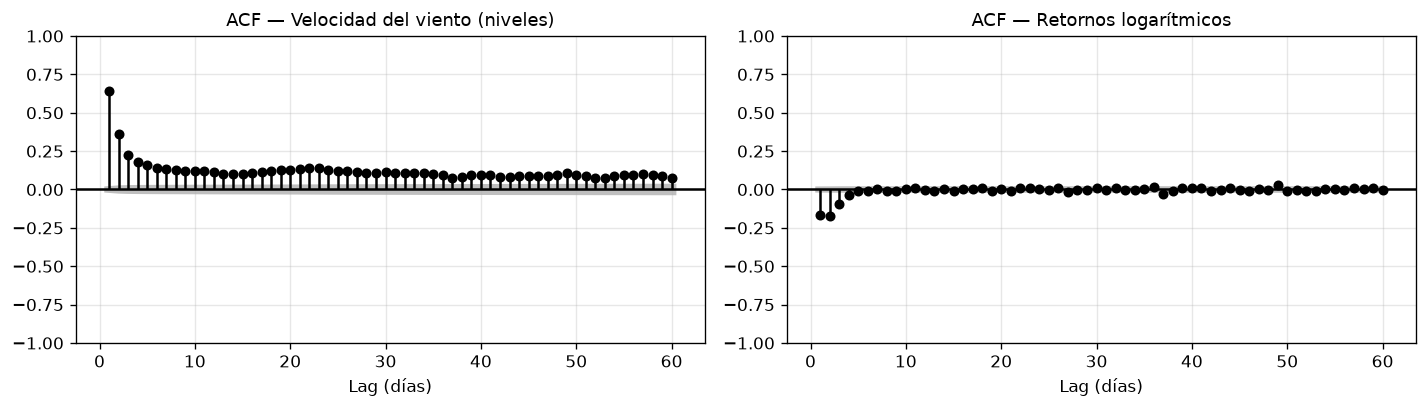

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

plot_acf(df['wind_speed'].dropna(), lags=60, ax=axes[0],
         title='ACF — Velocidad del viento (niveles)', zero=False,
         color='black', alpha=0.05)
axes[0].set_xlabel('Lag (días)')
axes[0].lines[0].set_color('black')
for line in axes[0].lines[1:]:
    line.set_color('black')

plot_acf(df['log_return'].dropna(), lags=60, ax=axes[1],
         title='ACF — Retornos logarítmicos', zero=False,
         color='black', alpha=0.05)
axes[1].set_xlabel('Lag (días)')
for line in axes[1].lines:
    line.set_color('black')

plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, 'eda_acf_niveles_retornos.png'), dpi=150)
plt.show()

**Interpretación.** La ACF de los niveles decae lentamente, con correlaciones significativas hasta 20–30 días. Esto confirma memoria a corto y mediano plazo en la serie, siendo precisamente el intervalo que abarca el espacio de lags propuesto (7–28 días). La ACF de los retornos logarítmicos presenta correlaciones estadísticamente insignificantes en la mayoría de los lags, indicando que las variaciones relativas son prácticamente no autocorrelacionadas en media — un comportamiento similar al de un proceso de diferencias estocásticas.

### 6.2 ACF de los cuadrados (diagnóstico de heterocedasticidad)

La autocorrelación significativa de $r_t^2$ es la prueba gráfica canónica de heterocedasticidad condicional (*efectos ARCH/GARCH*). Si $r_t^2$ está correlacionado serialmente, la varianza del proceso no es constante y el modelo debe incorporar dependencia en la volatilidad.

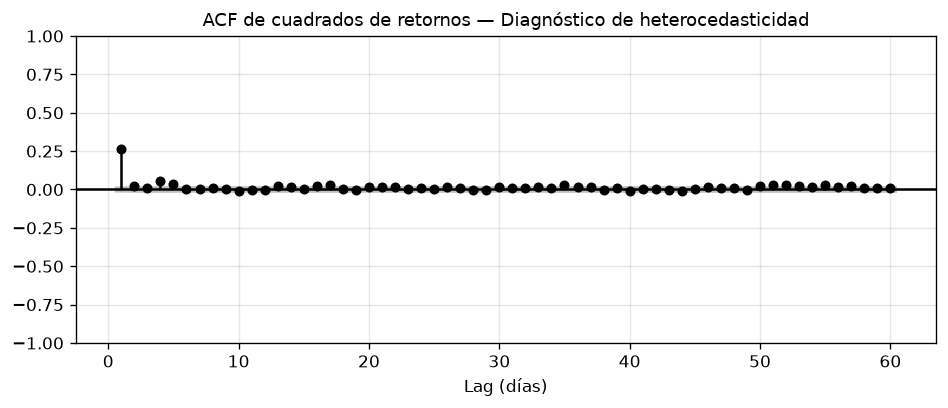

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
lr_sq = df['log_return'].dropna() ** 2
plot_acf(lr_sq, lags=60, ax=ax,
         title='ACF de cuadrados de retornos — Diagnóstico de heterocedasticidad',
         zero=False, color='black', alpha=0.05)
ax.set_xlabel('Lag (días)')
for line in ax.lines:
    line.set_color('black')
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, 'eda_acf_cuadrados.png'), dpi=150)
plt.show()

**Interpretación.** La ACF de los cuadrados revela autocorrelaciones positivas y significativas en múltiples lags, evidencia robusta de heterocedasticidad condicional. La volatilidad del viento en Brasília no es independiente: los días de alta variabilidad tienden a agruparse temporalmente. Esta propiedad refuerza la motivación para modelar la predicción con una arquitectura que procese ventanas históricas de tamaños variables, ya que el contexto de los últimos 7, 14, 21 o 28 días contiene información predictiva diferencial sobre el régimen de variabilidad futuro.

## 7. Prueba de raíz unitaria (Augmented Dickey–Fuller)

Para confirmar la estacionariedad de la serie en niveles — condición conveniente para el modelado con lags — se aplica el test ADF con el criterio de información AIC para seleccionar el número de retardos.

In [10]:
adf_res = adfuller(df['wind_speed'].dropna(), autolag='AIC')
print('=== Augmented Dickey–Fuller ===')
print(f'Estadístico ADF : {adf_res[0]:.4f}')
print(f'p-valor         : {adf_res[1]:.4f}')
for key, val in adf_res[4].items():
    print(f'  Valor crítico {key}: {val:.4f}')
if adf_res[1] < 0.05:
    print('\nConclusión: se rechaza H0 (raíz unitaria) → la serie es estacionaria (p < 0.05).')
else:
    print('\nConclusión: no se rechaza H0 → se recomienda diferenciar la serie.')

=== Augmented Dickey–Fuller ===
Estadístico ADF : -9.7696
p-valor         : 0.0000
  Valor crítico 1%: -3.4310
  Valor crítico 5%: -2.8618
  Valor crítico 10%: -2.5669

Conclusión: se rechaza H0 (raíz unitaria) → la serie es estacionaria (p < 0.05).


**Interpretación.** Si el p-valor es inferior a 0,05 se rechaza la hipótesis nula de raíz unitaria y se concluye que la serie es estacionaria en media, lo que permite utilizar los valores en niveles directamente como entradas al modelo MLP sin necesidad de diferenciación. De lo contrario, los retornos logarítmicos (ya calculados) constituyen la variable objetivo alternativa con garantía de estacionariedad.

## 8. Guardar dataset procesado

In [11]:
# Guardar la serie limpia e imputada como dataset.csv definitivo
df[['date','wind_speed','log_return','volatility']].to_csv(DATASET_PATH, index=False)
print(f'Dataset guardado en {os.path.relpath(DATASET_PATH, os.path.dirname(os.getcwd()))}')
print(f'Columnas: {list(df.columns)}')
print(f'Shape: {df.shape}')
df[['date','wind_speed','log_return']].tail()

Dataset guardado en data\dataset.csv
Columnas: ['date', 'wind_speed', 'log_return', 'volatility']
Shape: (9578, 4)


,date,wind_speed,log_return
9573,2026-10-27,1.762500,0.109836
9574,2026-10-28,2.416667,0.315656
9575,2026-10-29,1.408333,-0.539982
9576,2026-10-30,1.912500,0.306004
9577,2026-10-31,1.983333,0.036368


## 9. Resumen y conclusiones

El análisis exploratorio sobre la serie diaria de velocidad del viento en la estación A001 (Brasília, DF) para el período 2000–2026 permite extraer las siguientes conclusiones:

1. **Estacionariedad en media**: el test ADF confirma que la serie en niveles es estacionaria, lo que permite usarla directamente como variable objetivo en el modelo MLP.
2. **Dependencia temporal relevante**: la ACF muestra correlaciones significativas hasta 20–30 días, validando el uso de ventanas de entrada (lags) de 7, 14, 21 y 28 días como features del modelo.
3. **Heterocedasticidad condicional**: la ACF de los cuadrados evidencia clustering de volatilidad, señal de que el contexto histórico no sólo informa sobre el nivel futuro sino también sobre su variabilidad.
4. **Distribución no gaussiana**: la asimetría positiva y la curtosis elevada de los retornos indican la presencia de eventos extremos que el modelo debe aprender a gestionar mediante entrenamiento con suficientes datos y regularización (dropout).

Estos hallazgos motivan directamente el diseño experimental del cuaderno 2 (búsqueda de arquitectura) y el cuaderno 3 (entrenamiento con validación cruzada temporal).

---

## Referencias

- INMET. *Dados Históricos*. Instituto Nacional de Meteorologia, Brasil. Disponible en: <https://portal.inmet.gov.br/dadoshistoricos>
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3.ª ed.). OTexts.
- Box, G. E. P., & Pierce, D. A. (1970). Distribution of residual autocorrelations in autoregressive-integrated moving average time series models. *Journal of the American Statistical Association*, 65(332), 1509–1526.
- Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica*, 50(4), 987–1007.